# Paired data
`PairedData` holds `x` (shared by all curves), `y` `[n_curves, n_ordinates]` and optional curve labels.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))   # use the in-place build of the repo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyheclib as phl

plt.style.use('ggplot')
# restart the kernel if this is not the version / location you expect
print('pyheclib', phl.__version__, 'from', os.path.dirname(phl.__file__))

if os.path.exists('paired_data.dss'):
    os.remove('paired_data.dss')
dss_file = phl.open('paired_data.dss')
dss_file

pyheclib 0.4.0 from /Users/nzahasan/Development/pyheclib/pyheclib


<DssFile open 'paired_data.dss'>

In [2]:
h = np.linspace(0, 12, 25)
rating = phl.PairedData('/DEMO/OUTLET/STAGE-FLOW///RATING/', x=h,
                        y=np.vstack([5.2*h**1.8, 5.6*h**1.75, 6.1*h**1.7]),
                        x_unit='FT', y_unit='CFS', labels=['2018', '2019', '2020'])
dss_file.write(rating)

rating_read = dss_file.read(rating.path)
assert isinstance(rating_read, phl.PairedData)
np.testing.assert_allclose(rating_read.x, rating.x)
np.testing.assert_allclose(rating_read.y, rating.y)
assert rating_read.labels == rating.labels
rating_read.n_curves, rating_read.x_unit, rating_read.y_unit

(3, 'FT', 'CFS')

,2018,2019,2020
STAGE,,,
0.0,0.000000,0.000000,0.000000
0.5,1.493308,1.664890,1.877495
1.0,5.200000,5.600000,6.100000
1.5,10.788663,11.385385,12.153041
2.0,18.107452,18.836080,19.818958


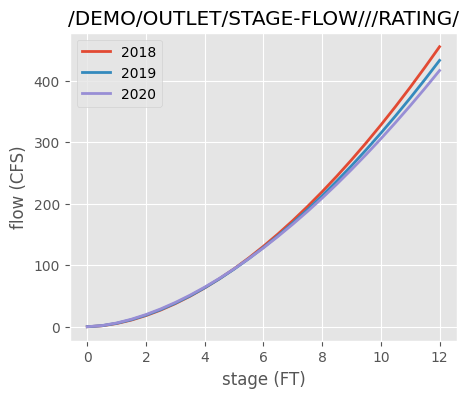

In [3]:
df = rating_read.to_dataframe()
ax = df.plot(figsize=(5, 4), lw=2, title=str(rating_read.path))
ax.set_xlabel('stage (FT)'); ax.set_ylabel('flow (CFS)')
df.head()

## From a DataFrame
The index is `x`, each column a curve, column names become labels.

In [4]:
curve = pd.DataFrame({'storage': [0, 120, 480, 1100, 2000.0]}, index=[100, 102, 104, 106, 108.0])
dss_file.write(phl.PairedData.from_dataframe('/DEMO/RESERVOIR/ELEVATION-STORAGE///TABLE/', curve, 'FT', 'AC-FT'))
out = dss_file.read('/DEMO/RESERVOIR/ELEVATION-STORAGE///TABLE/').to_dataframe()
np.testing.assert_allclose(out.values, curve.values)
out

,storage
ELEVATION,
100.0,0.0
102.0,120.0
104.0,480.0
106.0,1100.0
108.0,2000.0


In [5]:
dss_file.close()
print('all checks passed')

all checks passed
